
# Human Activity Recognition: Data Exploration

## Project Overview

This notebook explores the UCI Human Activity Recognition (HAR) dataset.

The objective is to understand the inertial sensor time-series data before developing a deep learning model using PyTorch.

## Dataset Information

- Dataset: UCI Human Activity Recognition Using Smartphones
- Training samples: 7,352
- Testing samples: 2,947
- Sensor channels: 6
- Time steps per sample: 128
- Sampling frequency: 50 Hz
- Activity classes: 6

## Exploration Objectives

1. Load the sensor signals and activity labels.
2. Understand the dataset dimensions.
3. Visualize accelerometer and gyroscope signals.
4. Compare sensor patterns across different activities.
5. Examine signal distributions and statistical properties.


In [ ]:
# Import project paths
import sys
from pathlib import Path

# Locate the project root
PROJECT_ROOT = Path.cwd().parent

# Add project root to Python's import path
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


from paths import (
    TRAIN_SIGNALS_DIR,
    TEST_SIGNALS_DIR,
    TRAIN_LABELS_FILE,
    TEST_LABELS_FILE,
    ACTIVITY_LABELS_FILE,
)

%matplotlib inline
print("Project root:", PROJECT_ROOT)


In [3]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Seaborn:", sns.__version__)

NumPy: 2.4.6
Pandas: 3.1.0
Matplotlib: 3.11.2
Seaborn: 0.13.2


In [4]:
# Define the sensor channels and activity labels
CHANNELS = [
    "body_acc_x",
    "body_acc_y",
    "body_acc_z",
    "body_gyro_x",
    "body_gyro_y",
    "body_gyro_z",
]

with open(ACTIVITY_LABELS_FILE, "r") as file:
    activity_labels = {
        int(line.split()[0]): line.split()[1]
        for line in file
    }

print("Sensor channels:")
for channel in CHANNELS:
    print("-", channel)

print("\nActivity labels:")
for activity_id, activity_name in activity_labels.items():
    print(f"{activity_id}: {activity_name}")

Sensor channels:
- body_acc_x
- body_acc_y
- body_acc_z
- body_gyro_x
- body_gyro_y
- body_gyro_z

Activity labels:
1: WALKING
2: WALKING_UPSTAIRS
3: WALKING_DOWNSTAIRS
4: SITTING
5: STANDING
6: LAYING


In [5]:
# Load the sensor signals
def load_signals(signals_dir, split):
    channel_data = []

    for channel in CHANNELS:
        file_path = signals_dir / f"{channel}_{split}.txt"
        data = np.loadtxt(file_path)
        channel_data.append(data)

    return np.stack(channel_data, axis=-1)


def load_labels(labels_file):
    return np.loadtxt(labels_file, dtype=int)


# Load training data
X_train = load_signals(TRAIN_SIGNALS_DIR, "train")
y_train = load_labels(TRAIN_LABELS_FILE)

# Load testing data
X_test = load_signals(TEST_SIGNALS_DIR, "test")
y_test = load_labels(TEST_LABELS_FILE)

print("Training signals:", X_train.shape)
print("Training labels:", y_train.shape)

print("Testing signals:", X_test.shape)
print("Testing labels:", y_test.shape)

Training signals: (7352, 128, 6)
Training labels: (7352,)
Testing signals: (2947, 128, 6)
Testing labels: (2947,)


## 1. Accelerometer Signal Visualization

We first examine the accelerometer measurements of a walking activity.

The accelerometer provides three signal channels:
- body_acc_x
- body_acc_y
- body_acc_z

Each channel contains 128 measurements collected over approximately 2.56 seconds.

In [6]:
# Find the first walking sample
walking_indices = np.where(y_train == 1)[0]

sample_index = walking_indices[0]

# Extract the selected sample
walking_sample = X_train[sample_index]

# Create time axis (50 Hz sampling frequency)
sampling_frequency = 50
time = np.arange(128) / sampling_frequency

print("Selected sample index:", sample_index)
print("Activity:", activity_labels[y_train[sample_index]])
print("Sample shape:", walking_sample.shape)

Selected sample index: 78
Activity: WALKING
Sample shape: (128, 6)


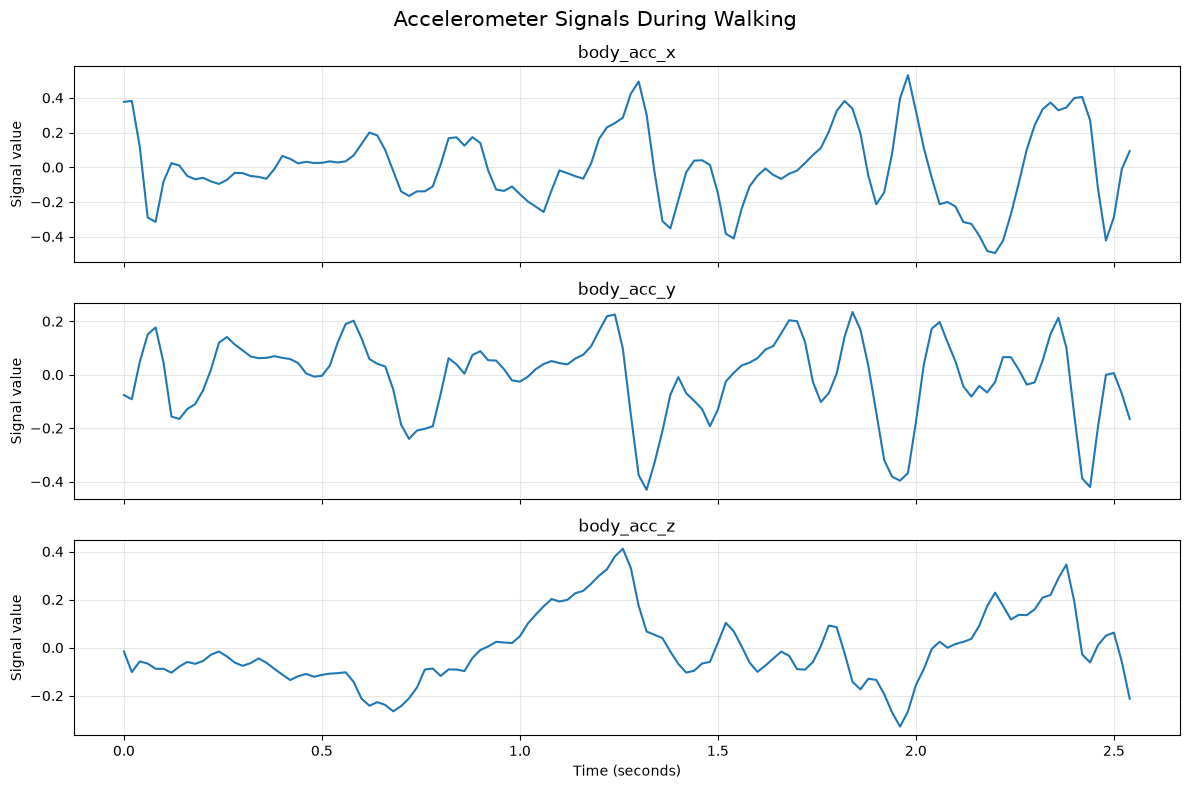

In [7]:
# Plot the three accelerometer axes
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

for i in range(3):
    axes[i].plot(time, walking_sample[:, i])
    axes[i].set_title(CHANNELS[i])
    axes[i].set_ylabel("Signal value")
    axes[i].grid(True, alpha=0.3)

axes[-1].set_xlabel("Time (seconds)")

fig.suptitle("Accelerometer Signals During Walking", fontsize=15)
plt.tight_layout()
plt.show()

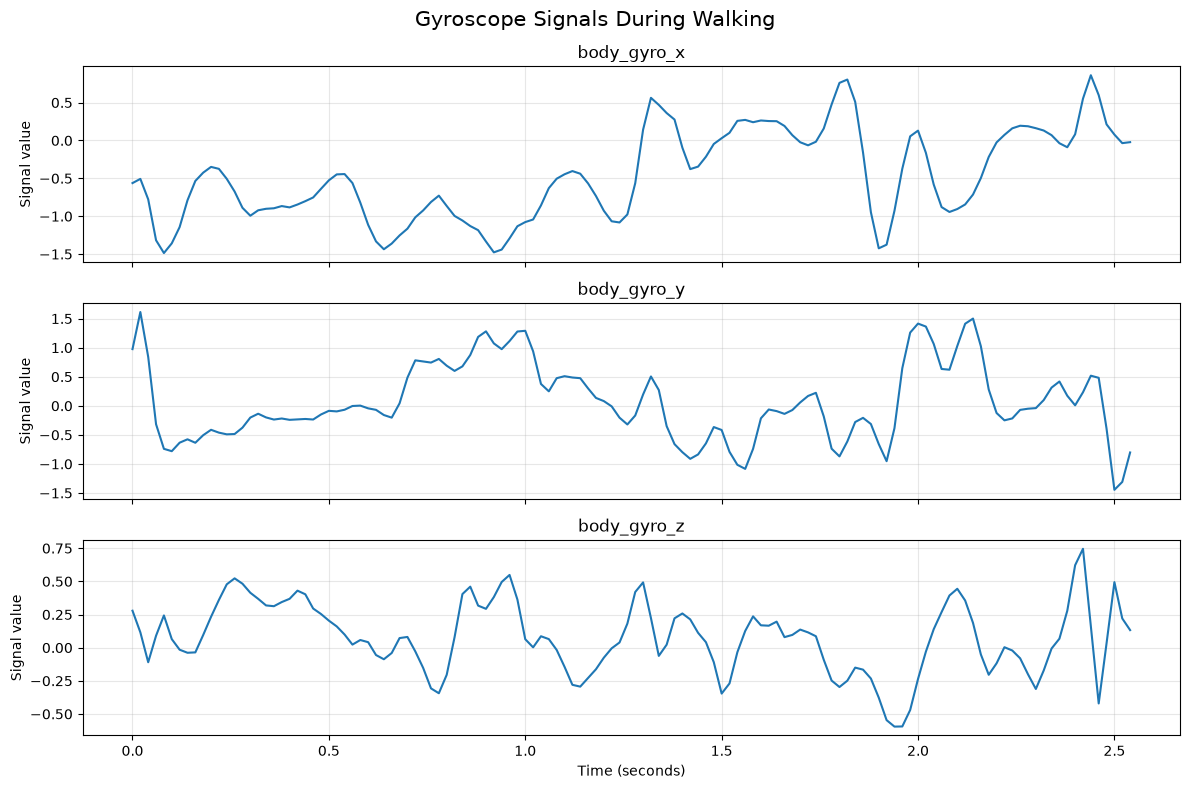

In [8]:
# Plot the gyroscope signals
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

for i in range(3):
    axes[i].plot(time, walking_sample[:, i + 3])
    axes[i].set_title(CHANNELS[i + 3])
    axes[i].set_ylabel("Signal value")
    axes[i].grid(True, alpha=0.3)

axes[-1].set_xlabel("Time (seconds)")

fig.suptitle("Gyroscope Signals During Walking", fontsize=15)
plt.tight_layout()
plt.show()

## 2. Comparing Sensor Signals Across Activities

In this section, we compare accelerometer signals from three activities:

- Walking
- Sitting
- Laying

We use the same sensor axis for each activity to examine how movement patterns differ.

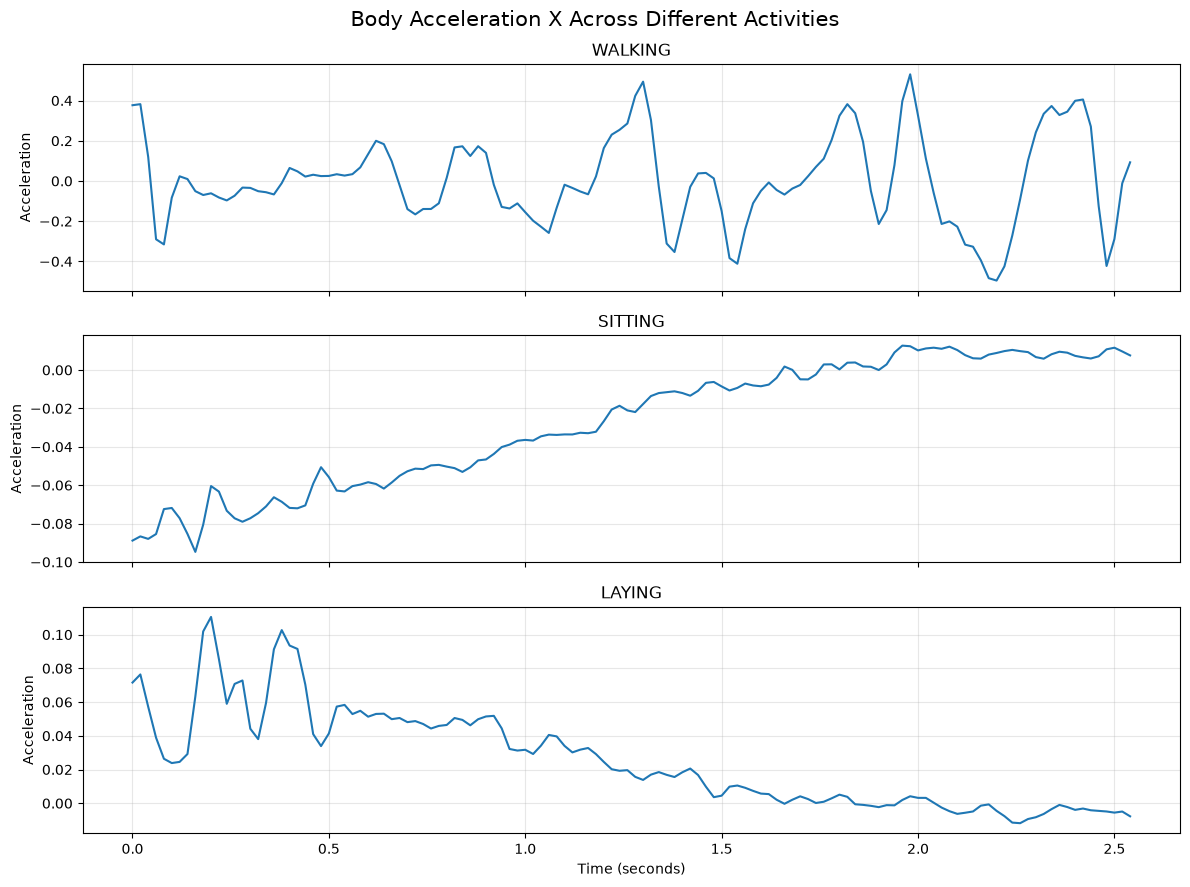

In [9]:
# Select one sample for each activity
activities_to_compare = {
    "WALKING": 1,
    "SITTING": 4,
    "LAYING": 6,
}

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

for ax, (activity_name, activity_id) in zip(
    axes, activities_to_compare.items()
):
    # Find the first sample belonging to this activity
    sample_idx = np.where(y_train == activity_id)[0][0]

    # Extract the body_acc_x channel
    signal = X_train[sample_idx, :, 0]

    ax.plot(time, signal)
    ax.set_title(activity_name)
    ax.set_ylabel("Acceleration")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time (seconds)")

fig.suptitle("Body Acceleration X Across Different Activities", fontsize=15)
plt.tight_layout()
plt.show()

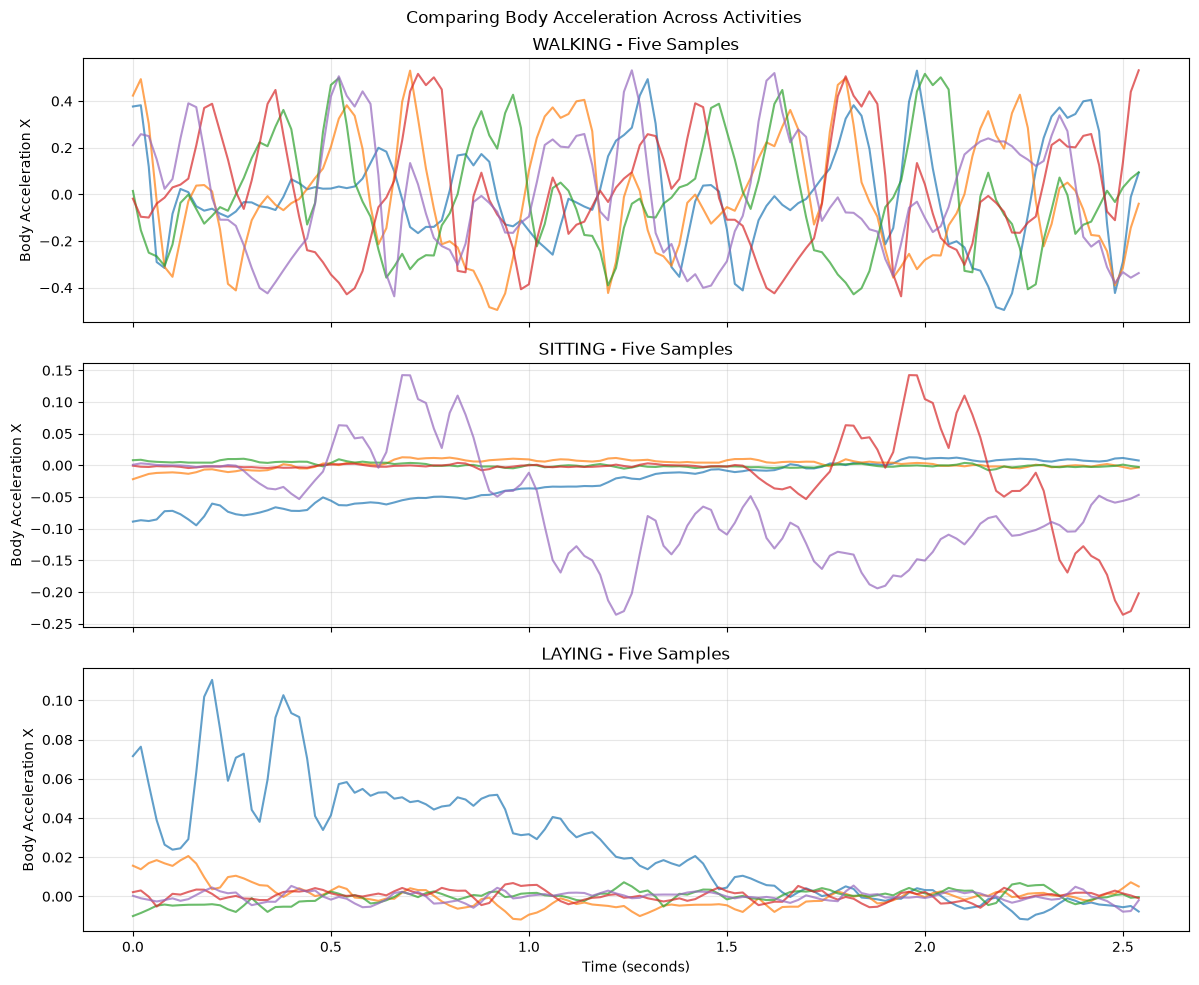

In [10]:
activities_to_compare = {
    "WALKING": 1,
    "SITTING": 4,
    "LAYING": 6,
}

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

for ax, (activity_name, activity_id) in zip(
    axes, activities_to_compare.items()
):
    indices = np.where(y_train == activity_id)[0][:5]

    for idx in indices:
        ax.plot(time, X_train[idx, :, 0], alpha=0.7)

    ax.set_title(f"{activity_name} - Five Samples")
    ax.set_ylabel("Body Acceleration X")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time (seconds)")

fig.suptitle("Comparing Body Acceleration Across Activities")
plt.tight_layout()
plt.show()

## 3. Statistical Analysis of Sensor Signals

We calculate the mean and standard deviation of each sensor channel
for every sample.

These statistics help us understand signal variation within and
between activity classes.

In [11]:
# Create a dataframe containing per-sample statistics
statistics = []

for sample_idx in range(len(X_train)):
    activity_id = y_train[sample_idx]

    for channel_idx, channel_name in enumerate(CHANNELS):
        signal = X_train[sample_idx, :, channel_idx]

        statistics.append({
            "activity": activity_labels[activity_id],
            "channel": channel_name,
            "mean": np.mean(signal),
            "std": np.std(signal),
        })

stats_df = pd.DataFrame(statistics)

# Display average statistics for each activity and channel
summary = (
    stats_df
    .groupby(["activity", "channel"])[["mean", "std"]]
    .mean()
    .round(4)
)

display(summary)

mean     std
activity           channel                    
LAYING             body_acc_x  -0.0017  0.0145
                   body_acc_y  -0.0006  0.0123
                   body_acc_z   0.0004  0.0135
                   body_gyro_x  0.0113  0.0318
                   body_gyro_y -0.0078  0.0299
                   body_gyro_z  0.0181  0.0208
SITTING            body_acc_x  -0.0009  0.0068
                   body_acc_y   0.0026  0.0126
                   body_acc_z   0.0006  0.0139
                   body_gyro_x -0.0105  0.0179
                   body_gyro_y  0.0007  0.0277
                   body_gyro_z -0.0035  0.0220
STANDING           body_acc_x   0.0004  0.0062
                   body_acc_y   0.0005  0.0126
                   body_acc_z   0.0003  0.0133
                   body_gyro_x  0.0014  0.0442
                   body_gyro_y  0.0037  0.0293
                   body_gyro_z -0.0033  0.0214
WALKING            body_acc_x  -0.0003  0.2239
                   body_acc_y  -0.0003  0.1684
                   body_acc_z  -0.0002  0.1380
                   body_gyro_x -0.0037  0.4690
                   body_gyro_y  0.0014  0.5163
                   body_gyro_z -0.0009  0.3298
WALKING_DOWNSTAIRS body_acc_x   0.0022  0.3703
                   body_acc_y   0.0004  0.1854
                   body_acc_z   0.0008  0.1520
                   body_gyro_x -0.0505  0.5942
                   body_gyro_y  0.0083  0.5311
                   body_gyro_z  0.0034  0.3584
WALKING_UPSTAIRS   body_acc_x  -0.0032  0.2535
                   body_acc_y  -0.0050  0.1718
                   body_acc_z  -0.0040  0.1570
                   body_gyro_x  0.0501  0.4688
                   body_gyro_y -0.0102  0.5193
                   body_gyro_z -0.0165  0.3695

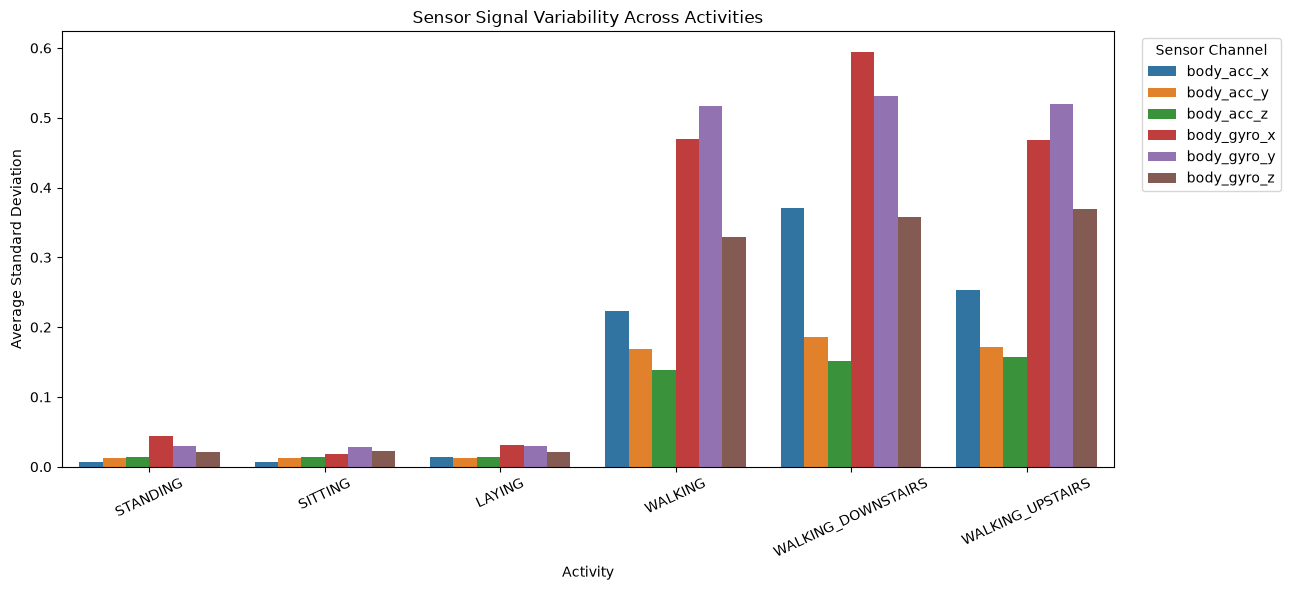

In [12]:
plt.figure(figsize=(13, 6))

sns.barplot(
    data=stats_df,
    x="activity",
    y="std",
    hue="channel",
    errorbar=None
)

plt.title("Sensor Signal Variability Across Activities")
plt.xlabel("Activity")
plt.ylabel("Average Standard Deviation")
plt.xticks(rotation=25)
plt.legend(title="Sensor Channel", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()


## 4. Distribution of Sensor Signal Variability

We compare the distribution of per-sample standard deviations
across all six activities.

This helps us understand:
- Within-class variation.
- Differences between activity classes.
- Potential overlap between activities.

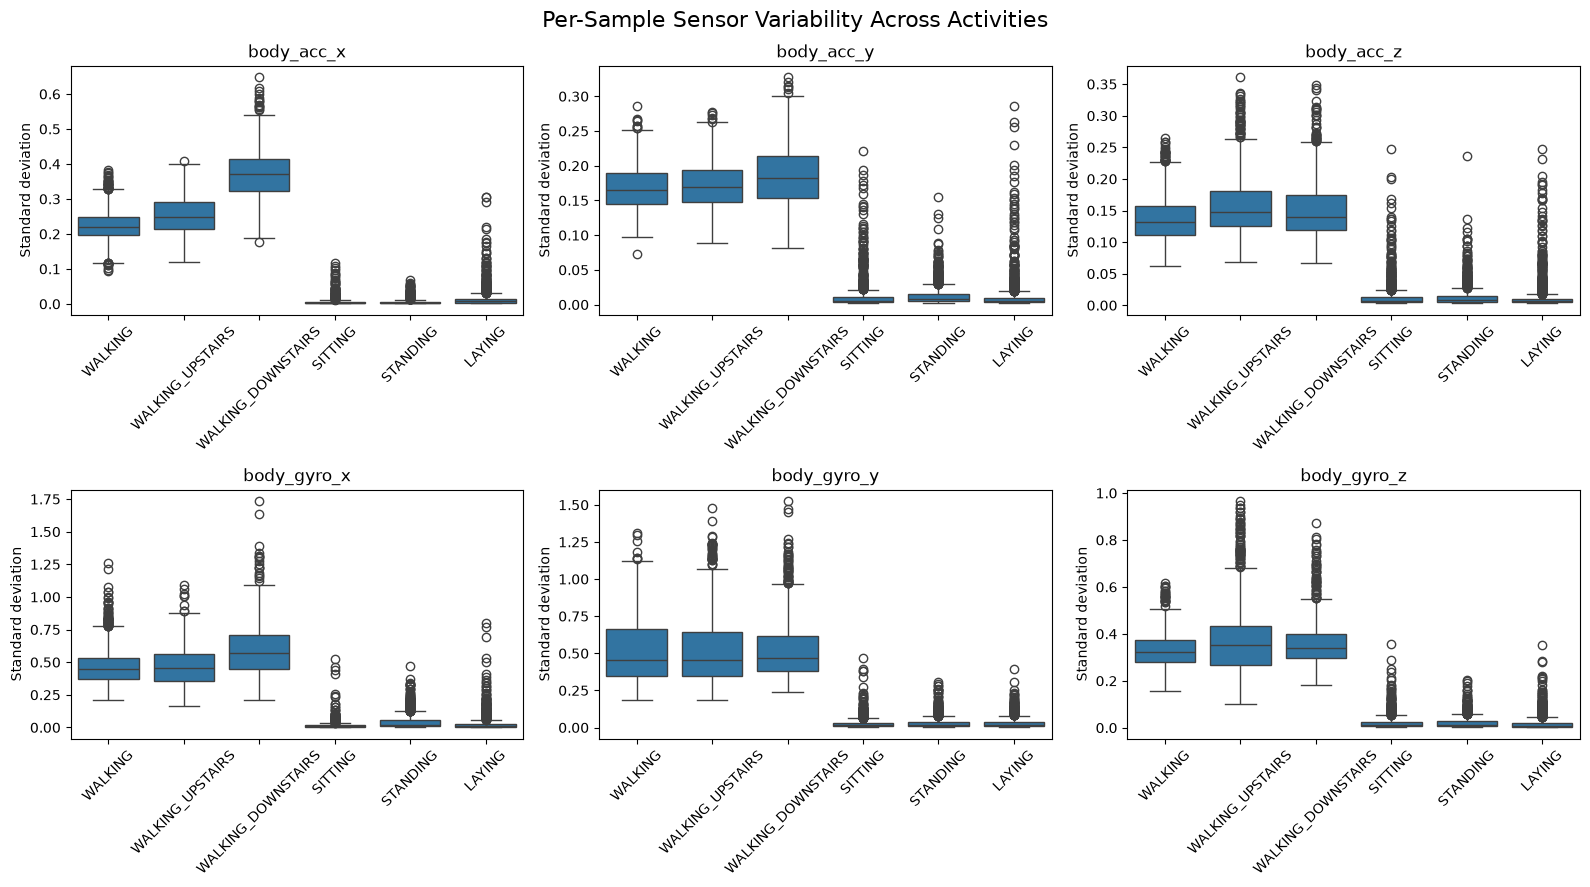

In [13]:
activity_order = [
    "WALKING",
    "WALKING_UPSTAIRS",
    "WALKING_DOWNSTAIRS",
    "SITTING",
    "STANDING",
    "LAYING",
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, channel in zip(axes.flat, CHANNELS):

    channel_data = stats_df[stats_df["channel"] == channel]

    sns.boxplot(
        data=channel_data,
        x="activity",
        y="std",
        order=activity_order,
        ax=ax
    )

    ax.set_title(channel)
    ax.set_xlabel("")
    ax.set_ylabel("Standard deviation")
    ax.tick_params(axis="x", rotation=45)

fig.suptitle(
    "Per-Sample Sensor Variability Across Activities",
    fontsize=16
)

plt.tight_layout()
plt.show()

## 5. Relationships Between Sensor Channels

We investigate relationships between sensor channels using
the correlation of their per-sample standard deviations.

This helps us understand whether different sensor channels
show similar patterns of variability across samples.

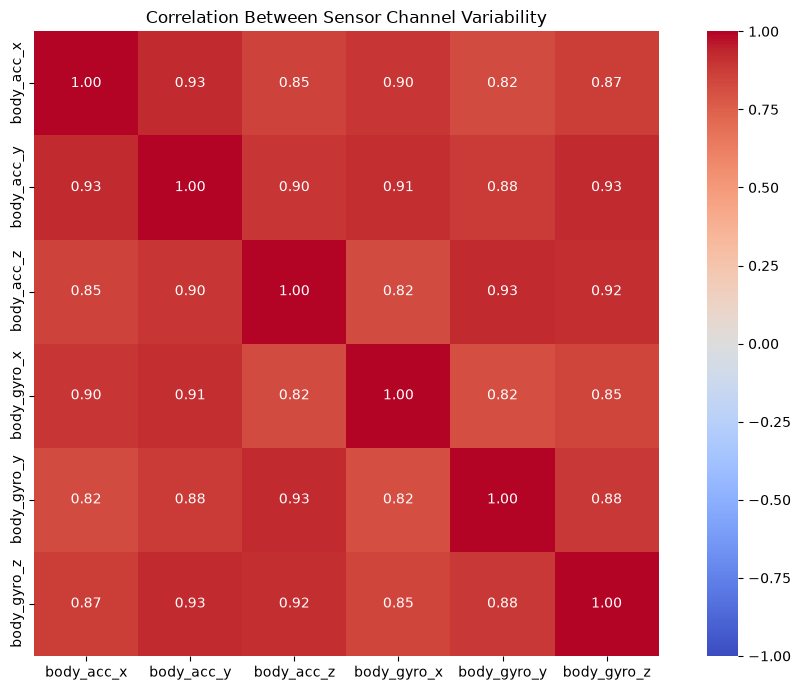

In [14]:
# Calculate standard deviation for each channel in every sample
# Shape: (7352 samples, 6 channels)
std_features = np.std(X_train, axis=1)

# Convert to DataFrame
std_df = pd.DataFrame(
    std_features,
    columns=CHANNELS
)

# Calculate channel correlation
correlation_matrix = std_df.corr()

# Visualize correlation
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Correlation Between Sensor Channel Variability")
plt.tight_layout()
plt.show()

## 6. Activity-Sensor Variability Heatmap

We compare the average per-sample standard deviation
across all six activities and six sensor channels.

This provides an overview of how sensor variability
changes between activity classes.

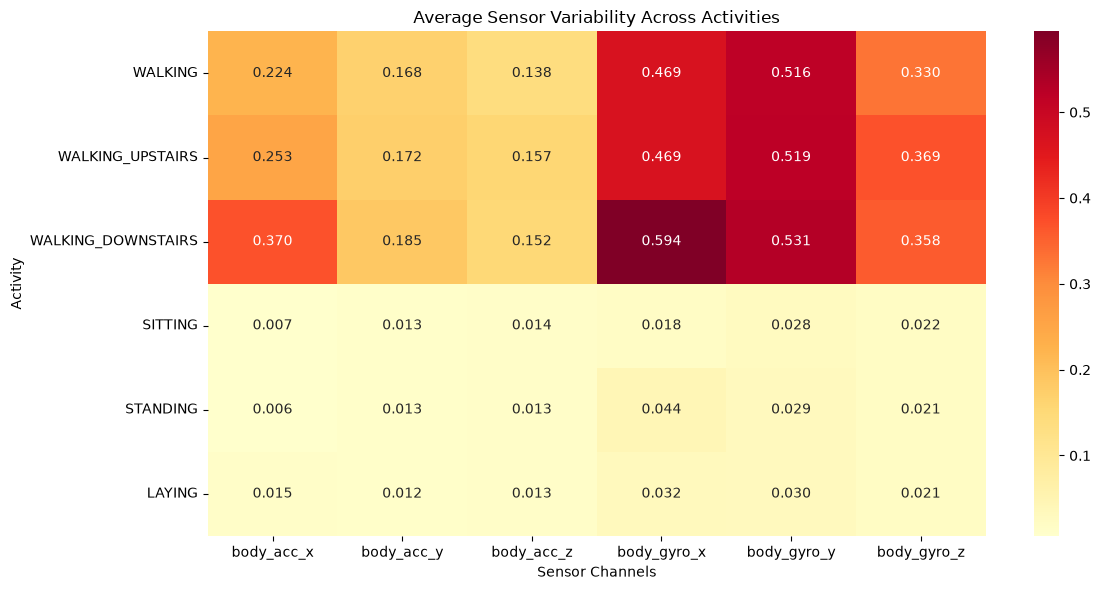

In [15]:
activity_order = [
    "WALKING",
    "WALKING_UPSTAIRS",
    "WALKING_DOWNSTAIRS",
    "SITTING",
    "STANDING",
    "LAYING",
]

variability_matrix = stats_df.pivot_table(
    index="activity",
    columns="channel",
    values="std",
    aggfunc="mean"
)

variability_matrix = variability_matrix.reindex(activity_order)

plt.figure(figsize=(12, 6))

sns.heatmap(
    variability_matrix,
    annot=True,
    cmap="YlOrRd",
    fmt=".3f"
)

plt.title("Average Sensor Variability Across Activities")
plt.xlabel("Sensor Channels")
plt.ylabel("Activity")
plt.tight_layout()
plt.show()